# When do summary metrics mislead? A stress test on clinical notes

Automatic metrics are the default way to evaluate generated clinical notes, but each one measures something narrower than "is this note clinically correct". This notebook tests four of them on clinical note sections from **MTS-Dialog** (doctor-patient conversations paired with the note section a clinician wrote; Ben Abacha et al., EACL 2023, CC BY 4.0):

| Metric | What it measures |
|---|---|
| **BLEU** | Overlap of word sequences (n-grams) with the reference, precision-oriented |
| **ROUGE-1 / ROUGE-2 / ROUGE-L** | Overlap of single words, word pairs, and the longest common word sequence, recall-oriented |
| **BERTScore** | Similarity of contextual embeddings (RoBERTa-large), so synonyms can match |
| **LLM-as-judge** | An LLM reads both notes and rates clinical accuracy from 1 to 5 |

Two analyses:
1. **Controlled edits.** Take each reference note and make small edits that either keep the clinical meaning (reorder sentences, paraphrase) or change it (flip a negation, change a number, swap left and right, drop a sentence, add an invented finding). A useful metric should penalize the harmful edits more than the harmless ones.
2. **Human judgments.** The dataset authors manually scored 400 model-generated summaries for factual precision, recall, hallucinations and omissions. We check how well each metric tracks those scores.

**Running it.** BLEU and ROUGE run anywhere. BERTScore downloads a model from Hugging Face on first use, and the LLM judge needs `ANTHROPIC_API_KEY`; cells for those two skip themselves when unavailable.

In [1]:
import os, sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from src.perturb import EDITS, apply_edit
from src.metrics import overlap_scores

RAW = Path("../data/raw")
RESULTS = Path("../data/results"); RESULTS.mkdir(parents=True, exist_ok=True)
OVERLAP = ["BLEU", "ROUGE-1", "ROUGE-2", "ROUGE-L"]

try:
    import bert_score  # noqa: F401
    HAS_BERTSCORE = True
except ImportError:
    HAS_BERTSCORE = False
HAS_JUDGE = bool(os.environ.get("ANTHROPIC_API_KEY"))
print(f"BERTScore available: {HAS_BERTSCORE}; LLM judge available: {HAS_JUDGE}")

/Users/rnorel/Documents/Learning/clinical-summary-metrics/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


BERTScore available: True; LLM judge available: True


## 1. Controlled edits

We use the official MEDIQA-Chat 2023 test set (200 note sections) and keep sections with at least 8 words, so that sentence-level edits are possible. Each edit is applied only where it makes sense (a left/right swap needs the words left or right).

In [2]:
notes = pd.read_csv(RAW / "MTS-Dialog-TestSet-1-MEDIQA-Chat-2023.csv")
notes = notes[notes["section_text"].str.split().str.len() >= 8].reset_index(drop=True)
print(f"{len(notes)} note sections; section types:")
notes["section_header"].value_counts().head(8)

132 note sections; section types:


section_header
GENHX            51
FAM/SOCHX        30
ROS              13
ASSESSMENT        7
PASTMEDICALHX     7
MEDICATIONS       5
CC                4
EDCOURSE          4
Name: count, dtype: int64

In [3]:
rows = []
for i, r in notes.iterrows():
    ref = r["section_text"].strip()
    for name, (group, _) in EDITS.items():
        cand = apply_edit(name, ref, i)
        if cand is None or cand == ref:
            continue
        rows.append({"note_id": r["ID"], "edit": name, "group": group, "reference": ref, "candidate": cand,
                     **overlap_scores(cand, ref)})
edits = pd.DataFrame(rows)
edits.groupby(["group", "edit"]).size().rename("notes edited").to_frame()

notes edited
group    edit                              
harmful  add invented finding           132
         change number                   65
         flip negation                   65
         omit last sentence              99
         swap left/right                 20
harmless paraphrase                      89
         reorder sentences               99

### Examples

One example per edit, so it is clear how small the harmful changes are on the page.

In [4]:
pd.set_option("display.max_colwidth", 160)
ex = edits.groupby("edit").head(1)[["edit", "reference", "candidate"]]
ex.assign(reference=ex["reference"].str[:150], candidate=ex["candidate"].str[:150])

,edit,reference,candidate
0,reorder sentences,"The patient is a 55-year-old African-American male that was last seen in clinic on 07/29/2008 with diagnosis of new onset seizures and an MRI scan, wh","Given the characteristics of this mass and his new onset seizures, it is significantly concerning for a high-grade glioma. The patient is a 55-year-ol"
1,paraphrase,"The patient is a 55-year-old African-American male that was last seen in clinic on 07/29/2008 with diagnosis of new onset seizures and an MRI scan, wh","This patient is a 55-year-old African-American male that was last seen in clinic on 07/29/2008 with diagnosis of new onset seizures and an MRI scan, w"
2,change number,"The patient is a 55-year-old African-American male that was last seen in clinic on 07/29/2008 with diagnosis of new onset seizures and an MRI scan, wh","The patient is a 75-year-old African-American male that was last seen in clinic on 07/29/2008 with diagnosis of new onset seizures and an MRI scan, wh"
3,swap left/right,"The patient is a 55-year-old African-American male that was last seen in clinic on 07/29/2008 with diagnosis of new onset seizures and an MRI scan, wh","The patient is a 55-year-old African-American male that was last seen in clinic on 07/29/2008 with diagnosis of new onset seizures and an MRI scan, wh"
4,omit last sentence,"The patient is a 55-year-old African-American male that was last seen in clinic on 07/29/2008 with diagnosis of new onset seizures and an MRI scan, wh","The patient is a 55-year-old African-American male that was last seen in clinic on 07/29/2008 with diagnosis of new onset seizures and an MRI scan, wh"
5,add invented finding,"The patient is a 55-year-old African-American male that was last seen in clinic on 07/29/2008 with diagnosis of new onset seizures and an MRI scan, wh","The patient is a 55-year-old African-American male that was last seen in clinic on 07/29/2008 with diagnosis of new onset seizures and an MRI scan, wh"
23,flip negation,He is retired from the social security administration x 20 years. He travels a lot and is extremely active. He does not smoke. He consumes alcohol,He is retired from the social security administration x 20 years. He travels a lot and is extremely active. He does smoke. He consumes alcohol soci


### BERTScore and LLM judge (optional)

BERTScore runs on every edited note. The LLM judge runs on every edit of a sample of 60 notes (all notes with a left/right swap, which are rare, plus random others), so that harmless and harmful versions of the same note can be compared, at a cost of about 260 API calls.

Results are cached in `data/results/` keyed by the text pair, so a rerun only scores pairs that are new (for example after changing an edit rule).

In [5]:
from tqdm import tqdm
KEY = ["reference", "candidate"]

def cached_scores(df, path, score_fn, cols, save_every=20):
    """Attach cached scores to df, scoring only (reference, candidate) pairs not yet in the cache."""
    cache = pd.read_csv(path) if path.exists() else pd.DataFrame(columns=KEY + cols)
    todo = df[KEY].drop_duplicates().merge(cache[KEY], on=KEY, how="left", indicator=True)
    todo = todo[todo["_merge"] == "left_only"][KEY]
    if len(todo) and score_fn is not None:
        new = []
        for i, (r, c) in enumerate(tqdm(list(zip(todo["reference"], todo["candidate"])), desc=path.stem)):
            new.append({"reference": r, "candidate": c, **score_fn(c, r)})
            if (i + 1) % save_every == 0 or i + 1 == len(todo):  # save as we go, so an interruption loses little
                cache = pd.concat([cache, pd.DataFrame(new)]).drop_duplicates(KEY, keep="last")
                cache.to_csv(path, index=False); new = []
    return df.merge(cache[KEY + cols].drop_duplicates(KEY), on=KEY, how="left")

# BERTScore: batch the missing pairs (much faster than one at a time)
bs_path = RESULTS / "edits_bertscore.csv"
if HAS_BERTSCORE or bs_path.exists():
    cache = pd.read_csv(bs_path) if bs_path.exists() else pd.DataFrame(columns=KEY + ["BERTScore"])
    todo = edits[KEY].drop_duplicates().merge(cache[KEY], on=KEY, how="left", indicator=True)
    todo = todo[todo["_merge"] == "left_only"][KEY]
    if len(todo) and HAS_BERTSCORE:
        from src.metrics import bertscore
        todo = todo.assign(BERTScore=bertscore(todo["candidate"].tolist(), todo["reference"].tolist()))
        cache = pd.concat([cache, todo]); cache.to_csv(bs_path, index=False)
    edits = edits.merge(cache.drop_duplicates(KEY), on=KEY, how="left")
else:
    print("BERTScore not available: skipping")

# LLM judge on all edits of a 60-note sample
judge_path = RESULTS / "edits_judge.csv"
swap_notes = list(edits.loc[edits["edit"] == "swap left/right", "note_id"].unique())
others = sorted(set(edits["note_id"]) - set(swap_notes))
pick = swap_notes + list(np.random.default_rng(0).choice(others, 60 - len(swap_notes), replace=False))
judged = edits[edits["note_id"].isin(pick)]
if HAS_JUDGE or judge_path.exists():
    from src.metrics import llm_judge
    fn = (lambda c, r: {"judge_score": (o := llm_judge(c, r)).get("score"), "judge_reason": o.get("reason")}) if HAS_JUDGE else None
    judged = cached_scores(judged, judge_path, fn, ["judge_score", "judge_reason"])
    print(f"LLM judge: {judged['judge_score'].notna().sum()} of {len(judged)} edited notes scored ({len(pick)} notes)")
else:
    judged = None
    print("LLM judge not available: skipping")
METRICS = OVERLAP + (["BERTScore"] if "BERTScore" in edits else [])

LLM judge: 283 of 283 edited notes scored (60 notes)


### How much does each metric drop?

An unedited note scores 100 on every overlap metric. The table shows the average score after each edit. Read it row by row: harmless edits should stay near 100, harmful ones should drop clearly. Averages hide the key question, though, which the next section answers directly.

In [6]:
order = ["reorder sentences", "paraphrase", "flip negation", "change number", "swap left/right",
         "omit last sentence", "add invented finding"]
summary = edits.groupby(["group", "edit"])[METRICS].mean().round(1)
summary

BLEU  ROUGE-1  ROUGE-2  ROUGE-L  BERTScore
group    edit                                                            
harmful  add invented finding  77.7     87.1     86.3     87.1       85.5
         change number         94.6     97.5     95.0     97.5       98.2
         flip negation         92.7     98.2     94.9     98.2       96.0
         omit last sentence    70.4     84.1     83.0     84.1       81.1
         swap left/right       92.4     97.0     93.4     96.8       99.0
harmless paraphrase            86.9     93.8     88.7     93.8       96.7
         reorder sentences     92.5    100.0     92.2     44.1       80.6

### Does the metric prefer the clinically wrong note?

The direct test: for the same note, does the metric give the **harmful** version a higher score than a **harmless** rewrite? We compare every harmful/harmless pair within a note (ties count as half). A good metric should almost never prefer the wrong note: 0% is perfect, 50% is a coin flip.

The LLM judge column uses its 60-note sample; it scores 1 to 5, so ties are more common and count as half a mistake.

In [7]:
HARMFUL = order[2:]

def prefers_wrong(df, metric):
    """% of within-note (harmful, harmless) pairs where the harmful version scores higher (ties = 0.5)."""
    res = {}
    for name in HARMFUL:
        w = []
        for _, g in df.groupby("note_id"):
            harmless = g.loc[g["group"] == "harmless", metric].dropna()
            for h in g.loc[g["edit"] == name, metric].dropna():
                w += [(h > s) + 0.5 * (h == s) for s in harmless]
        res[name] = np.mean(w) * 100 if w else np.nan
    return pd.Series(res)

wrong = pd.DataFrame({m: prefers_wrong(edits, m) for m in METRICS})
if judged is not None:
    wrong["LLM judge"] = prefers_wrong(judged, "judge_score")
wrong.loc["all harmful edits"] = wrong.mean()
wrong = wrong[wrong.loc["all harmful edits"].sort_values(ascending=False).index]
wrong.round(0)

,ROUGE-L,BERTScore,ROUGE-2,BLEU,ROUGE-1,LLM judge
flip negation,98.0,73.0,83.0,75.0,46.0,1.0
change number,93.0,89.0,74.0,76.0,41.0,3.0
swap left/right,88.0,97.0,64.0,56.0,41.0,0.0
omit last sentence,65.0,29.0,33.0,18.0,12.0,12.0
add invented finding,67.0,45.0,50.0,26.0,15.0,0.0
all harmful edits,82.0,67.0,61.0,50.0,31.0,3.0


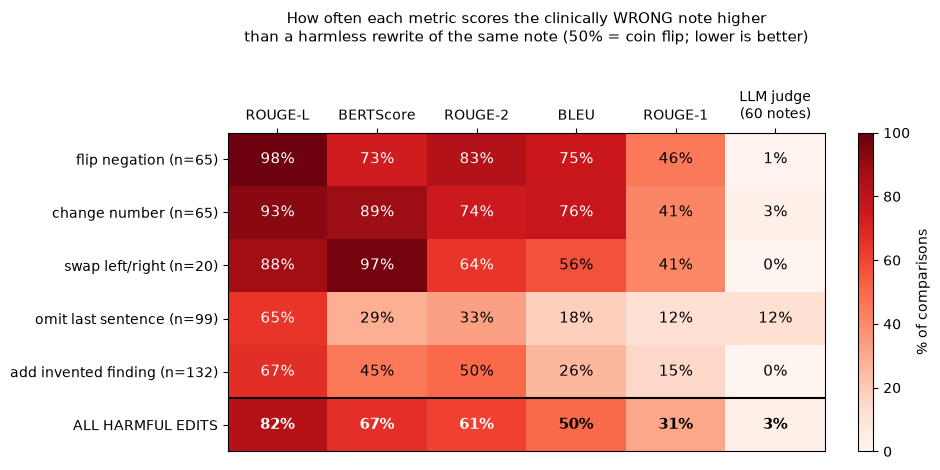

In [8]:
n_notes = edits[edits["group"] == "harmful"].groupby("edit")["note_id"].nunique()
labels = [f"{e} (n={n_notes[e]})" for e in HARMFUL] + ["ALL HARMFUL EDITS"]
cols = [c if c != "LLM judge" else "LLM judge\n(60 notes)" for c in wrong.columns]
fig, ax = plt.subplots(figsize=(9.5, 4.8))
im = ax.imshow(wrong.values, cmap="Reds", vmin=0, vmax=100, aspect="auto")
for (r, c), v in np.ndenumerate(wrong.values):
    ax.text(c, r, "" if np.isnan(v) else f"{v:.0f}%", ha="center", va="center", fontsize=11,
            color="white" if v > 60 else "black", fontweight="bold" if r == len(wrong) - 1 else "normal")
ax.axhline(len(wrong) - 1.5, color="black", lw=1.5)
ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, fontsize=10); ax.xaxis.tick_top()
ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels, fontsize=10)
ax.set_title("How often each metric scores the clinically WRONG note higher\n"
             "than a harmless rewrite of the same note (50% = coin flip; lower is better)", fontsize=11, pad=34)
fig.colorbar(im, ax=ax, fraction=.03).set_label("% of comparisons")
fig.tight_layout(); fig.savefig("../reports/figures/metric_prefers_wrong_note.png", dpi=150)

### LLM judge on the same edits

The judge scores clinical accuracy from 1 to 5: a perfect judge would give 5 to harmless edits and 2 or lower to harmful ones. The reasons it gives are in `data/results/edits_judge.csv`.

In [9]:
if judged is not None:
    jt = judged.groupby(["group", "edit"])["judge_score"].agg(["count", "mean", lambda s: (s.dropna() <= 2).mean() * 100])
    jt.columns = ["notes", "mean score (1-5)", "% scored as important error (<= 2)"]
    display(jt.round(1))
else:
    print("No judge results yet. Set ANTHROPIC_API_KEY and rerun to fill this section.")

notes  mean score (1-5)  \
group    edit                                            
harmful  add invented finding     60               2.0   
         change number            32               2.5   
         flip negation            34               2.1   
         omit last sentence       49               3.7   
         swap left/right          20               2.0   
harmless paraphrase               39               5.0   
         reorder sentences        49               4.7   

                               % scored as important error (<= 2)  
group    edit                                                      
harmful  add invented finding                                98.3  
         change number                                       53.1  
         flip negation                                       91.2  
         omit last sentence                                   0.0  
         swap left/right                                    100.0  
harmless paraphrase                                           0.0  
         reorder sentences                                    0.0

## 2. Agreement with human factual judgments

The MTS-Dialog authors had annotators count facts in 400 automatic summaries (4 models x 100 validation conversations) and computed factual precision, recall, F1, hallucination rate and omission rate. We correlate each automatic metric with those human scores (Spearman). A metric that tracks clinical quality should correlate positively with factual F1 and negatively with hallucination and omission rates.

In [10]:
auto = pd.read_csv(RAW / "MTS-Dialog-Automatic-Summaries-ValidationSet.csv")
human = pd.read_csv(RAW / "MTS-Dialog-Manual-Scores4CorrelationStudy.csv")
corr_df = pd.concat([auto, human], axis=1)
scores = pd.DataFrame([overlap_scores(str(c), str(r)) for c, r in
                       zip(corr_df["Automatic Summary"], corr_df["Reference Summary"])])
corr_df = pd.concat([corr_df, scores], axis=1)

bs2 = RESULTS / "human_bertscore.csv"
if bs2.exists():
    corr_df["BERTScore"] = pd.read_csv(bs2)["BERTScore"].to_numpy()
elif HAS_BERTSCORE:
    from src.metrics import bertscore
    corr_df["BERTScore"] = bertscore(corr_df["Automatic Summary"].astype(str).tolist(),
                                     corr_df["Reference Summary"].astype(str).tolist())
    corr_df[["BERTScore"]].to_csv(bs2, index=False)

j2 = RESULTS / "human_judge.csv"
if j2.exists():
    corr_df["LLM judge"] = pd.read_csv(j2)["LLM judge"].to_numpy()
elif HAS_JUDGE:
    from src.metrics import llm_judge
    corr_df["LLM judge"] = [llm_judge(str(c), str(r)).get("score") for c, r in
                            tqdm(list(zip(corr_df["Automatic Summary"], corr_df["Reference Summary"])), desc="judge: human set")]
    corr_df[["LLM judge"]].to_csv(j2, index=False)

auto_metrics = [m for m in OVERLAP + ["BERTScore", "LLM judge"] if m in corr_df]
human_cols = ["FactualF1", "FactualPrecision", "FactualRecall", "HallucinationRate", "OmissionRate"]
corr = pd.DataFrame({h: {m: spearmanr(corr_df[m], corr_df[h], nan_policy="omit")[0] for m in auto_metrics}
                     for h in human_cols}).round(2)
corr

,FactualF1,FactualPrecision,FactualRecall,HallucinationRate,OmissionRate
BLEU,0.52,0.13,0.51,-0.01,-0.51
ROUGE-1,0.36,0.04,0.35,-0.01,-0.47
ROUGE-2,0.02,-0.02,0.01,0.03,-0.12
ROUGE-L,0.36,0.07,0.36,-0.02,-0.46
BERTScore,0.55,0.21,0.54,-0.11,-0.56
LLM judge,0.62,0.37,0.61,-0.16,-0.54


### Can the metric flag a hallucinated summary?

Treat each metric as a detector: a low score should flag the summaries where annotators found at least one hallucinated fact. AUROC is the probability that a random hallucinated summary scores lower than a random clean one (0.5 = chance, 1 = perfect).

In [11]:
from scipy.stats import mannwhitneyu
has_halluc = corr_df["HallucinationRate"] > 0
def auroc_low_flags(score, y):
    ok = score.notna()
    pos, neg = score[ok & y], score[ok & ~y]
    return mannwhitneyu(neg, pos).statistic / (len(pos) * len(neg))  # P(clean scores higher than hallucinated)
print(f"{has_halluc.sum()} of {len(corr_df)} summaries have at least one hallucinated fact")
pd.Series({m: auroc_low_flags(corr_df[m], has_halluc) for m in auto_metrics}, name="hallucination AUROC").round(2).to_frame()

33 of 400 summaries have at least one hallucinated fact


,hallucination AUROC
BLEU,0.51
ROUGE-1,0.50
ROUGE-2,0.47
ROUGE-L,0.52
BERTScore,0.61
LLM judge,0.66


### Where overlap metrics and human judgments disagree

Summaries that score well on ROUGE-L but contain hallucinations are the dangerous case: an overlap-based leaderboard would rank them as good.

In [12]:
risky = corr_df[(corr_df["HallucinationRate"] > 0)].sort_values("ROUGE-L", ascending=False)
print(f"{(corr_df['HallucinationRate'] > 0).mean():.0%} of automatic summaries contain at least one hallucinated fact")
risky[["Reference Summary", "Automatic Summary", "ROUGE-L", "HallucinationRate"]].head(5).assign(
    **{"Reference Summary": lambda d: d["Reference Summary"].str[:120],
       "Automatic Summary": lambda d: d["Automatic Summary"].str[:120]}).round(2)

8% of automatic summaries contain at least one hallucinated fact


,Reference Summary,Automatic Summary,ROUGE-L,HallucinationRate
334,Mother died at the age of 59 due to stomach cancer and father died at the age of 91 years old.,Mother died of gastric carcinoma at the age of 59. Father died of alcoholism at age 91.,63.16,0.17
348,"No headaches. No visual, hearing, or swallowing difficulties. No changes in bowel or urinary habits.","NEUROLOGIC: Normal; Negative for headaches, vertigo, visual obscurations, swallowing difficulties, or changes in bowel o",62.50,0.17
176,"There was no history of hypertension, coronary artery disease, stroke, cancer or diabetes.","Noncontributory. No family history of heart disease, stroke, cancer, or hypertension.",58.33,0.20
110,"She was born, normal spontaneous vaginal delivery at Woman's weighing 7 pounds 3 ounces. No complications. Prevented,",The baby was born at the Women's Hospital at 7.3 pounds 3 ounces with no cesarean section. There were no complications.,45.16,0.17
248,"No headaches. No visual, hearing, or swallowing difficulties. No changes in bowel or urinary habits.","CONSTITUTIONAL: No history of hearing loss, dysphagia, swallowing difficulties, dysuria, headaches, visual double vision",42.11,0.22


## Takeaways

The README has the full write-up. In short:
- **Overlap and embedding metrics often prefer the clinically wrong note.** Single-word errors (a flipped negation, a changed number, a swapped side) barely change BLEU, ROUGE or BERTScore; ROUGE-L even punishes harmless reordering more than any harmful edit.
- **BERTScore handles paraphrase but not factual errors:** left and right, or two different numbers, are close in embedding space.
- **The LLM judge was the only metric that reliably caught the controlled edits, and it tracked human factual F1 best on real summaries.** But its rubric names the error types tested here, so the real-summary analysis is the fairer test, and there its advantage is smaller.
- **No metric flagged hallucinated real summaries well** (AUROC at or below 0.66). Use overlap metrics as cheap regression checks, add targeted checks for negation, numbers and laterality, and validate any LLM judge against clinician review.